# Spark Architecture & Lazy Evaluation (PySpark)

pandas and DuckDB process data on one machine. When the data is larger than the memory or the disk of one machine,
you must split the work over many machines. **Apache Spark** is the most used open-source engine for this. It splits
a dataset into **partitions**, sends one **task** per partition to the workers, and combines the results.
You write the query once; the same code runs on a laptop or on a cluster of hundreds of machines.

This lesson runs Spark in **local mode** (one process on this machine). The concepts are the same as on a cluster.
You measure what Spark does: how many jobs, stages and tasks one query makes, how the run time changes with the
number of cores, and how Spark compares with pandas and DuckDB on one machine.

**After this lesson you can:**

1. Explain the driver, executors, cores, partitions and tasks, and what `local[N]` means.
2. Separate transformations from actions and show that Spark builds a plan before it runs anything.
3. Read the jobs, stages and tasks of a query from the Spark REST API.
4. Measure the effect of cores and caching, and say when Spark is the right tool.

**Data:** NYC yellow taxi trips, January 2024 (2.96 million rows, one 50 MB Parquet file).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import os
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pyspark
import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "l01"
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir(parents=True)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"                 # no hostname warning
LOG4J = WORK / "log4j2.properties"                           # only errors from the JVM, no start-up messages
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
                 "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n"
                 "logger.repl.name = org.apache.spark.repl.Main\nlogger.repl.level = error\n")
TRIPS = str(shutil.copy(datasets.taxi("2024-01"), WORK / "trips_2024-01.parquet"))   # local disk: fair timings

def start_spark(cores: int = 4) -> SparkSession:
    """One local Spark process with `cores` task threads."""
    s = (SparkSession.builder.master(f"local[{cores}]").appName(f"m13-l01-local{cores}")
         .config("spark.driver.memory", "1200m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j.configurationFile=file:{LOG4J} -XX:MaxDirectMemorySize=256m").getOrCreate())
    s.sparkContext.setLogLevel("ERROR")
    return s

def api(path: str):
    """GET from the Spark REST API of the running application."""
    sc = spark.sparkContext
    return requests.get(f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}", timeout=10).json()

def run_tagged(tag: str, action):
    """Run an action under a job group; return (result, seconds)."""
    sc = spark.sparkContext
    sc.setJobGroup(tag, tag)
    t0 = time.perf_counter()
    result = action()
    secs = time.perf_counter() - t0
    sc.setLocalProperty("spark.jobGroup.id", None)
    return result, secs

def jobs_and_stages(tag: str):
    """Jobs of one job group and their completed stages (the REST API is updated asynchronously)."""
    time.sleep(0.5)
    jobs = []
    for _ in range(50):
        jobs = [j for j in api("jobs") if j.get("jobGroup") == tag]
        if jobs and all(j["status"] != "RUNNING" for j in jobs):
            break
        time.sleep(0.2)
    ids = sorted({s for j in jobs for s in j["stageIds"]})
    stages = [a for sid in ids for a in api(f"stages/{sid}?details=false") if a["status"] == "COMPLETE"]
    return sorted(jobs, key=lambda j: j["jobId"]), stages

spark = start_spark(4)
print("Spark", pyspark.__version__, "| master:", spark.sparkContext.master, "| UI:", spark.sparkContext.uiWebUrl)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.2.0 | master: local[4] | UI: http://localhost:4040


## 1. Driver, Executors, Cores and Partitions

A Spark application has two kinds of processes:

| Part | What it does | In `local[4]` |
| :--- | :--- | :--- |
| **Driver** | Runs your Python code, builds the plan, splits it into tasks, collects results | this notebook's JVM |
| **Executor** | Runs tasks and keeps cached data | the same JVM as the driver |
| **Core (task slot)** | One task runs on one core at a time | 4 threads |
| **Partition** | One piece of the data; one task processes one partition | depends on the input files |
| **Task** | The work for one partition in one stage | one per partition |

`local[N]` means: driver and executor are one JVM process on this machine with N task threads.
`local[*]` uses all cores. On a cluster, the master is a cluster manager (Kubernetes, YARN, Spark standalone), and
each executor is a separate JVM on a worker machine. PySpark sends your DataFrame code to the JVM;
the data stays in the JVM unless you use Python UDFs or collect results.

In [2]:
sc = spark.sparkContext
trips = spark.read.parquet(TRIPS)
execs = api("executors")
print(f"default parallelism (task slots): {sc.defaultParallelism}")
print(f"executors seen by the REST API:   {[(e['id'], e['totalCores']) for e in execs]}")
print(f"input partitions of the file:     {trips.rdd.getNumPartitions()}")
print(f"columns: {len(trips.columns)}, e.g. {trips.columns[:6]}")

default parallelism (task slots): 4
executors seen by the REST API:   [('driver', 4)]


input partitions of the file:     4
columns: 19, e.g. ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID']


In local mode the REST API shows a single executor with the id `driver`: the driver also runs the tasks.
The number of input partitions comes from the file size and the number of cores (Lesson 03 explains the rule).

## 2. Transformations and Actions: Lazy Evaluation

A **transformation** (`filter`, `withColumn`, `groupBy().agg()`, `join`) returns a new DataFrame. It does not read
data; it only adds a step to the **plan**. An **action** (`count`, `collect`, `show`, `write`, `toPandas`) needs a
result, so Spark optimizes the plan and runs it. This is **lazy evaluation**. It lets Spark see the whole query
before it starts, so it can skip columns and rows that the result does not need.

The cell defines the aggregation of this lesson: trips and revenue per pickup zone per day.
It measures the time to define the query and the number of Spark jobs before and after the action.

In [3]:
def zone_day(df):
    """Trips and revenue per pickup zone per day, January 2024."""
    return (df.filter((F.col("tpep_pickup_datetime") >= "2024-01-01") & (F.col("tpep_pickup_datetime") < "2024-02-01"))
              .withColumn("day", F.to_date("tpep_pickup_datetime"))
              .groupBy("PULocationID", "day")
              .agg(F.count("*").alias("trips"), F.round(F.sum("total_amount"), 2).alias("revenue")))

query, t_define = run_tagged("define", lambda: zone_day(spark.read.parquet(TRIPS)))
define_jobs, _ = jobs_and_stages("define")
result, t_action = run_tagged("lazy-demo", query.collect)
action_jobs, _ = jobs_and_stages("lazy-demo")
print(f"define the query: {t_define * 1000:7.1f} ms, Spark jobs: {len(define_jobs)} {[j['name'][:40] for j in define_jobs]}")
print(f"collect():        {t_action * 1000:7.1f} ms, Spark jobs: {len(action_jobs)}, rows returned: {len(result):,}")

define the query:   808.9 ms, Spark jobs: 1 ['parquet at NativeMethodAccessorImpl.java']
collect():         3934.2 ms, Spark jobs: 2, rows returned: 6,949


Defining the query took 809 ms and started one small Spark job (`parquet at ...`). This job reads only the file
footer to get the schema; it reads no rows. All the work happens in `collect()`: 3.9 s and 2 jobs. This first run
also includes the time to generate code for the query, so later runs are faster. The plan that Spark runs is visible with `explain()`; read it from the
bottom up: scan the file, filter, compute the day, partial aggregation, **Exchange** (the shuffle), final aggregation.

In [4]:
query.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 1
   +- *(2) HashAggregate(keys=[PULocationID#26, day#39], functions=[count(1), sum(total_amount#35)])
      +- AQEShuffleRead coalesced
         +- ShuffleQueryStage 0
            +- Exchange hashpartitioning(PULocationID#26, day#39, 8), ENSURE_REQUIREMENTS, [plan_id=44]
               +- *(1) HashAggregate(keys=[PULocationID#26, day#39], functions=[partial_count(1), partial_sum(total_amount#35)])
                  +- *(1) Project [PULocationID#26, total_amount#35, cast(tpep_pickup_datetime#20 as date) AS day#39]
                     +- *(1) Filter ((isnotnull(tpep_pickup_datetime#20) AND (tpep_pickup_datetime#20 >= 2024-01-01 00:00:00)) AND (tpep_pickup_datetime#20 < 2024-02-01 00:00:00))
                        +- *(1) ColumnarToRow
                           +- FileScan parquet [tpep_pickup_datetime#20,PULocationID#26,total_amount#35] Batched: true, DataFilters: [isnotnull(tpep_pickup_dat

## 3. Jobs, Stages and Tasks

Spark turns each action into one or more **jobs**. A job is split into **stages** at every shuffle: all rows with
the same key must move to the same task before the final aggregation. A stage has one **task** per partition.

| Level | Created by | Boundary |
| :--- | :--- | :--- |
| Job | an action (with adaptive execution, one job per shuffle stage) | the action |
| Stage | a chain of narrow steps | a shuffle (Exchange) |
| Task | one partition of a stage | runs on one core |

The cell runs the zone-day aggregation again under a job group and reads the jobs, stages and tasks from the REST API.

In [5]:
query = zone_day(spark.read.parquet(TRIPS))                # a new DataFrame: nothing to reuse
rows, secs = run_tagged("zone-day", query.collect)
jobs, stages = jobs_and_stages("zone-day")
print(f"{len(rows):,} result rows in {secs:.2f} s")
print(f"jobs: {len(jobs)}, stages run: {len(stages)}, tasks: {sum(s['numTasks'] for s in stages)}")
print(pd.DataFrame([{"job": j["jobId"], "stages": j["stageIds"], "tasks": j["numTasks"], "skipped stages": j["numSkippedStages"]}
                    for j in jobs]).to_string(index=False))
print()
print(pd.DataFrame([{"stage": s["stageId"], "tasks": s["numTasks"], "input rows": s["inputRecords"], "shuffle write KB": round(s["shuffleWriteBytes"] / 1e3, 1),
                     "shuffle read KB": round(s["shuffleReadBytes"] / 1e3, 1),
                     "task time s": round(s["executorRunTime"] / 1000, 2)} for s in stages]).to_string(index=False))

6,949 result rows in 0.85 s
jobs: 2, stages run: 2, tasks: 5


 job stages  tasks  skipped stages
   5    [6]      4               0
   6 [7, 8]      5               1

 stage  tasks  input rows  shuffle write KB  shuffle read KB  task time s
     6      4     2964624             186.5              0.0         1.38
     8      1           0               0.0            186.5         0.04


In [6]:
scan = max(stages, key=lambda s: s["inputRecords"])
tasks = api(f"stages/{scan['stageId']}/{scan['attemptId']}/taskList?length=100")
print(f"tasks of the scan stage {scan['stageId']}:")
print(pd.DataFrame([{"task": t["index"], "input rows": t["taskMetrics"]["inputMetrics"]["recordsRead"],
                     "duration ms": t["duration"]} for t in sorted(tasks, key=lambda t: t["index"])]).to_string(index=False))

tasks of the scan stage 6:
 task  input rows  duration ms
    0     1048576          509
    1     1048576          444
    2           0           57
    3      867472          452


In [7]:
_, secs_again = run_tagged("zone-day-again", query.collect)   # the same DataFrame object a second time
jobs2, stages2 = jobs_and_stages("zone-day-again")
print(f"same DataFrame again: {secs_again:.2f} s, stages run: {len(stages2)}, "
      f"skipped stages: {sum(j['numSkippedStages'] for j in jobs2)}, tasks: {sum(s['numTasks'] for s in stages2)}")

same DataFrame again: 0.12 s, stages run: 1, skipped stages: 1, tasks: 1


The query made 2 jobs, 2 stages and 5 tasks. The first stage (4 tasks) scans the file. Each task makes a
**partial aggregation**, so the stage writes only 186.5 KB to the shuffle: one row per (zone, day) and task, not
3 million rows. The second stage reads the shuffle and makes the final
aggregation. With adaptive execution (on by default, Lesson 02), Spark runs the shuffle stage as its own job first,
then plans the rest with the real sizes. The per-task table shows a detail that matters in Section 4:
the file has only **3 row groups**, and a Parquet task reads whole row groups. One of the 4 scan tasks reads no rows.

The second time, the same DataFrame object took 0.12 s: Spark kept the shuffle files of the first run and
**skipped** the scan stage. To time a query fairly, build a new DataFrame for each run (the cells below do this).

## 4. More Cores: Scaling

The cell runs the same query with `local[1]`, `local[2]` and `local[4]`. Each run starts a new Spark session (the
old one is stopped first). Each setting has one warm-up run and then the best of 2 timed runs.
Local-mode timings are indicative: other programs on the machine change them by a few percent.

 cores  best s  scan tasks  tasks with rows  speed-up
     1    0.62           1                1      1.00
     2    0.52           2                2      1.19
     4    0.42           4                3      1.48


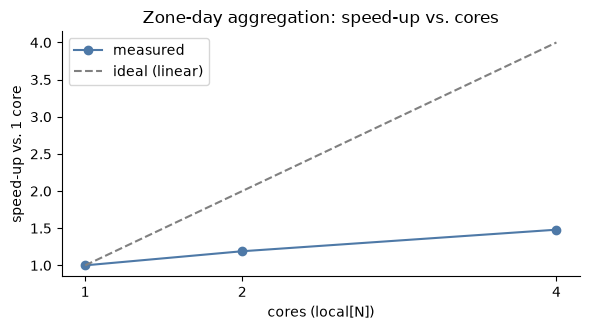

In [8]:
scaling = []
for cores in [1, 2, 4]:
    spark.stop()
    spark = start_spark(cores)
    fresh = lambda: zone_day(spark.read.parquet(TRIPS)).collect()   # new DataFrame each time: no shuffle reuse
    fresh()                                                # warm-up: JVM code generation, file cache
    times = [run_tagged(f"scale-{cores}-{i}", fresh)[1] for i in range(2)]
    _, st = jobs_and_stages(f"scale-{cores}-0")
    scan = max(st, key=lambda s: s["inputRecords"])
    tl = api(f"stages/{scan['stageId']}/{scan['attemptId']}/taskList?length=100")
    busy = sum(t["taskMetrics"]["inputMetrics"]["recordsRead"] > 0 for t in tl)
    scaling.append({"cores": cores, "best s": round(min(times), 2), "scan tasks": scan["numTasks"], "tasks with rows": busy})
scaling = pd.DataFrame(scaling)
scaling["speed-up"] = (scaling["best s"].iloc[0] / scaling["best s"]).round(2)
print(scaling.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(scaling.cores, scaling["speed-up"], "o-", color="#4E79A7", label="measured")
ax.plot(scaling.cores, scaling.cores, "--", color="grey", label="ideal (linear)")
ax.set(title="Zone-day aggregation: speed-up vs. cores", xlabel="cores (local[N])", ylabel="speed-up vs. 1 core",
       xticks=[1, 2, 4]); ax.legend()
plt.tight_layout(); plt.show()

*Insight: 4 cores made the query 1.48x faster (0.62 s to 0.42 s), not 4x. Two reasons are in the table: the file has only 3 row groups, so at most 3 tasks read rows; and a fixed part of each query (planning, scheduling, the final stage, sending the result to Python) does not run in parallel. On a cluster, network and task start-up add more fixed cost.*

This fixed, serial part limits the speed-up (**Amdahl's law**): if a fraction $s$ of the work is serial,
the speed-up with $N$ cores is at most

$$\text{speed-up}(N) = \frac{1}{s + (1 - s)/N}.$$

Spark scales well when each task has a lot of work, that is, for large data with many partitions.

## 5. Caching

Every action reads the file again. If you use the same intermediate result many times (in exploration, or in an
iterative algorithm), `cache()` keeps it in executor memory. `cache()` is lazy too: the first action fills the
cache, later actions read from memory. The cell caches an intermediate result
and times 3 aggregations without and with the cache (best of 2).
It does this for two intermediate results: 3 plain columns of the file, and a cleaned table that is joined with
the zone names and has two computed columns.

In [9]:
zones = spark.read.csv(str(datasets.fetch("taxi_zone_lookup.csv")), header=True, inferSchema=True)
plain = spark.read.parquet(TRIPS).select("tpep_pickup_datetime", "PULocationID", "total_amount")
enriched = (spark.read.parquet(TRIPS)                       # a more expensive intermediate result
            .filter((F.col("trip_distance") > 0) & (F.col("fare_amount") > 0))
            .join(zones.withColumnRenamed("LocationID", "PULocationID"), "PULocationID")
            .withColumn("minutes", (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)
            .withColumn("tip_pct", F.col("tip_amount") / F.col("fare_amount") * 100)
            .select("tpep_pickup_datetime", "PULocationID", "Borough", "total_amount", "minutes", "tip_pct"))

def three_queries(df):
    zone_day(df).collect()
    df.groupBy("PULocationID").count().collect()
    df.agg(F.sum("total_amount")).collect()

def best2(fn):
    fn()                                                    # warm-up
    times = []
    for _ in range(2):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

cache_rows = []
for name, df in [("3 columns of the Parquet file", plain), ("filtered + joined + new columns", enriched)]:
    t_plain = best2(lambda: three_queries(df))
    cached = df.cache()
    _, t_fill = run_tagged(f"fill-{name}", cached.count)
    t_cached = best2(lambda: three_queries(cached))
    mem = api("storage/rdd")
    cache_rows.append({"intermediate": name, "3 queries, no cache s": round(t_plain, 2), "fill cache s": round(t_fill, 2),
                       "3 queries, cached s": round(t_cached, 2), "cache MB": round(sum(r["memoryUsed"] for r in mem) / 1e6, 1)})
    cached.unpersist(blocking=True)
print(pd.DataFrame(cache_rows).to_string(index=False))

                   intermediate  3 queries, no cache s  fill cache s  3 queries, cached s  cache MB
  3 columns of the Parquet file                   0.57          1.15                 0.49      50.7
filtered + joined + new columns                   1.30          1.94                 0.53     101.0


*Insight: The cache gave almost nothing for 3 plain Parquet columns (0.57 s to 0.49 s). Reading them from a local Parquet file is already fast. For the filtered and joined intermediate result, the cache cut the time by more than half (1.30 s to 0.53 s). Filling the cache costs time (1.15 s and 1.94 s) and memory (50.7 MB and 101.0 MB). Cache only results that are expensive to compute and that you use more than twice.*

Call `unpersist()` when you no longer need the data. Cached data that does not fit in memory is evicted or,
with `persist(StorageLevel.MEMORY_AND_DISK)`, written to local disk.

## 6. Reality Check: pandas and DuckDB

Spark is built for data that does not fit on one machine. On 3 million rows, a single-machine engine has no
network, no task scheduling and no JVM. The cell runs the same aggregation with pandas and with DuckDB,
checks that all three engines give the same result, and compares the best of 2 times.

Spark local[4]    0.36 s  groups: 6,949  same groups as DuckDB: True  max |trips diff|: 0  max |revenue diff|: 0.0000
pandas            0.39 s  groups: 6,949  same groups as DuckDB: True  max |trips diff|: 0  max |revenue diff|: 0.0000
DuckDB            0.08 s  groups: 6,949  same groups as DuckDB: True  max |trips diff|: 0  max |revenue diff|: 0.0000


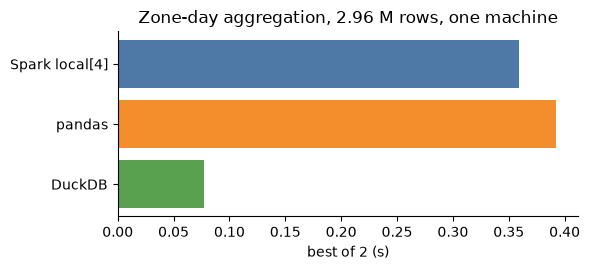

In [10]:
def pandas_zone_day():
    df = pd.read_parquet(TRIPS, columns=["tpep_pickup_datetime", "PULocationID", "total_amount"])
    df = df[(df.tpep_pickup_datetime >= "2024-01-01") & (df.tpep_pickup_datetime < "2024-02-01")]
    return (df.assign(day=df.tpep_pickup_datetime.dt.normalize()).groupby(["PULocationID", "day"])
              .agg(trips=("total_amount", "size"), revenue=("total_amount", "sum")).reset_index())

def duckdb_zone_day():
    return duckdb.sql(f"""
        SELECT PULocationID, CAST(tpep_pickup_datetime AS DATE) AS day, COUNT(*) AS trips, SUM(total_amount) AS revenue
        FROM '{TRIPS}'
        WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-02-01'
        GROUP BY ALL""").df()

engines = {"Spark local[4]": lambda: zone_day(spark.read.parquet(TRIPS)).toPandas(), "pandas": pandas_zone_day, "DuckDB": duckdb_zone_day}
timing, out = {}, {}
for name, fn in engines.items():
    out[name] = fn()                                        # warm-up
    ts = []
    for _ in range(2):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    timing[name] = min(ts)

def norm(df):
    df = df.assign(day=pd.to_datetime(df["day"]), PULocationID=df.PULocationID.astype(int))
    return df.set_index(["PULocationID", "day"]).sort_index()[["trips", "revenue"]].astype(float)

ref = norm(out["DuckDB"])
for name in engines:
    other = norm(out[name])
    same_keys = other.index.equals(ref.index)
    diff = (other - ref).abs().max() if same_keys else None
    print(f"{name:<15} {timing[name]:6.2f} s  groups: {len(other):,}  same groups as DuckDB: {same_keys}  "
          f"max |trips diff|: {diff['trips']:.0f}  max |revenue diff|: {diff['revenue']:.4f}")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(list(timing), list(timing.values()), color=["#4E79A7", "#F28E2B", "#59A14F"])
ax.set(title="Zone-day aggregation, 2.96 M rows, one machine", xlabel="best of 2 (s)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

*Insight: All three engines return the same 6,949 groups with the same trips and revenue. DuckDB was the fastest (0.08 s). Spark took 0.36 s and pandas 0.39 s, both about 5x slower than DuckDB. On 3 million rows that fit in memory, Spark is not the fastest tool: its fixed cost per query is larger than the work. Spark is for data that does not fit on one machine, where the other two cannot run at all.*

## Real-World Use Case or Analogy

Spark is like a **head chef with a team of cooks**. The head chef (driver) reads the whole order (the plan) before
anybody starts. The chef splits the work into stations (stages) and gives each cook (core) one tray of ingredients
(partition) at a time. Nothing is cooked until a guest asks for a plate (an action). For one sandwich, one person
in a home kitchen (pandas, DuckDB) is faster than a full restaurant team.

Companies use Spark when one machine is not enough: daily batch jobs over terabytes of click logs, the
"silver" and "gold" layers of a lakehouse (M12), feature tables for machine learning, and backfills of years of data.
Databricks, AWS EMR and Google Dataproc run Spark as a managed service. For data that fits in one machine's memory,
many teams now use DuckDB or Polars instead and keep Spark for the large jobs.

In [11]:
spark.stop()